In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor


SEED = 42
np.random.seed(SEED)

## Part A. Data Inspection and Potential Leakage

In [12]:
df = pd.read_csv("hybrid_student_performance_1200.csv")

print("The dataset shape : ", df.shape)
print("\n\nData types : \n")
df.info()

The dataset shape :  (1200, 36)


Data types : 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 36 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              1200 non-null   object 
 1   timestamp               1200 non-null   object 
 2   year_class              1200 non-null   object 
 3   program_stream          1200 non-null   object 
 4   age                     1200 non-null   int64  
 5   gender                  1200 non-null   object 
 6   cgpa_category           1200 non-null   object 
 7   academic_satisfaction   1200 non-null   object 
 8   study_hours_daily       1200 non-null   object 
 9   daily_productivity      1166 non-null   float64
 10  revision_frequency      1166 non-null   object 
 11  focus_duration          1157 non-null   object 
 12  screen_time_non_study   1168 non-null   object 
 13  main_distractor         1200 non-null   obje

In [8]:
print(df.describe())
missing = (df.isna().mean() * 100).round(2)
missing = missing[missing > 0].sort_values(ascending=False)
print("\n\nMissing % per column:")
print(missing)

               age  daily_productivity  energy_level  stress_level  \
count  1200.000000         1166.000000   1172.000000   1165.000000   
mean     20.807500            2.686964      3.227816      3.151931   
std       2.186953            1.178761      1.145359      1.189194   
min      17.000000            1.000000      1.000000      1.000000   
25%      19.000000            2.000000      2.000000      2.000000   
50%      21.000000            3.000000      3.000000      3.000000   
75%      22.000000            3.000000      4.000000      4.000000   
max      26.000000            5.000000      5.000000      5.000000   

       routine_rating  
count     1159.000000  
mean         2.105263  
std          0.788057  
min          1.000000  
25%          1.000000  
50%          2.000000  
75%          3.000000  
max          3.000000  


Missing % per column:
events_participation      4.83
sleep_hours               4.58
external_resources        3.75
focus_duration            3.58
routi

In [14]:
#convert timestamp to datetime

df["timestamp"] = pd.to_datetime(df["timestamp"])

print(df["timestamp"].dtype)
print("Range :", df["timestamp"].min(), "->", df["timestamp"].max())

datetime64[ns]
Range : 2026-03-15 01:07:00 -> 2026-04-14 22:27:00


In [17]:
# DUPLICATES

# 1- fully identical rows
print("All columns:           ", df.duplicated().sum())

# 2- identical with student_id and without timestamp
print("Ignoring timestamp:    ", df.drop(columns=["timestamp"]).duplicated().sum())

# 3- identical answers only
print("Ignoring both:         ", df.drop(columns=["student_id", "timestamp"]).duplicated().sum())

All columns:            0
Ignoring timestamp:     0
Ignoring both:          0


### Building the target variable "final_gpa"

In [24]:
#check text values

cols_to_encode = ["cgpa_category", "study_hours_daily", "sleep_hours",
                  "attendance_percentage", "study_consistency", "tasks_on_time",
                  "assignments_on_time", "revision_frequency", "career_goal_clarity"]

for c in cols_to_encode:
    print(c, "->", df[c].dropna().unique())


def clean(s):
    """lowercase, unify dashes, remove spaces and % so text matches easily"""
    return (s.astype("string").str.lower()
             .str.replace("–", "-").str.replace("—", "-")
             .str.replace(" ", "").str.replace("%", ""))
#encoding
def encode(col, mapping):
    out = clean(df[col]).map(mapping).astype(float)
    bad = df[col].notna() & out.isna()      # had an answer, but not mapped
    if bad.any():
        print(f"!! {col}: unmapped ->", df.loc[bad, col].unique())
    return out

cgpa_category -> ['8.5 – 9.4' '5.0 – 6.9' '9.5 – 10.0' '7.0 – 8.4']
study_hours_daily -> ['Less than 1 hour' '1–2 hours' 'More than 2 hours']
sleep_hours -> ['6–7 hours' '4–5 hours' 'More than 8 hours']
attendance_percentage -> ['Above 85%' '76% – 85%' 'Less than 50%' '50% – 65%' '66% – 75%']
study_consistency -> ['Rarely' 'Sometimes' 'Mostly consistent']
tasks_on_time -> ['Sometimes' 'Often' 'Always' 'Rarely']
assignments_on_time -> ['Often' 'Sometimes' 'Always' 'Rarely']
revision_frequency -> ['Never' 'Rarely' 'Few times a week' 'Daily']
career_goal_clarity -> ['Somewhat clear' 'Very clear' 'Not clear']


In [26]:
# build final_cpga and encoded features

data = pd.DataFrame()
data["student_id"] = df["student_id"]
data["timestamp"]  = df["timestamp"]

# target
data["final_cgpa"] = encode("cgpa_category",
    {"5.0-6.9": 5.95, "7.0-8.4": 7.70, "8.5-9.4": 8.95, "9.5-10.0": 9.75})

# midpoints
data["study_hours"] = encode("study_hours_daily",
    {"lessthan1hour": 0.5, "1-2hours": 1.5, "morethan2hours": 2.5})
data["sleep_hours"] = encode("sleep_hours",
    {"4-5hours": 4.5, "6-7hours": 6.5, "morethan8hours": 8.5})
data["attendance_rate"] = encode("attendance_percentage",
    {"lessthan50": 40, "50-65": 57.5, "66-75": 70.5, "76-85": 80.5, "above85": 92.5})

# ordinals
data["study_consistency"] = encode("study_consistency",
    {"rarely": 0, "sometimes": 1, "mostlyconsistent": 2})
data["tasks_on_time"] = encode("tasks_on_time",
    {"rarely": 0, "sometimes": 1, "often": 2, "always": 3})
data["assignments_on_time"] = encode("assignments_on_time",
    {"rarely": 0, "sometimes": 1, "often": 2, "always": 3})
data["revision_frequency"] = encode("revision_frequency",
    {"never": 0, "rarely": 1, "fewtimesaweek": 2, "daily": 3})
data["career_goal_clarity"] = encode("career_goal_clarity",
    {"notclear": 0, "somewhatclear": 1, "veryclear": 2})

# already numeric features
for c in ["daily_productivity", "stress_level", "age"]:
    data[c] = df[c]

# days since first submission
data["submission_day"] = (data["timestamp"] - data["timestamp"].min()).dt.total_seconds() / 86400
#keep label
data["performance_risk_level"] = df["performance_risk_level"]

#percentage of missing values
print(data.isna().mean().mul(100).round(2))

student_id                0.00
timestamp                 0.00
final_cgpa                0.00
study_hours               0.00
sleep_hours               4.58
attendance_rate           0.00
study_consistency         0.00
tasks_on_time             0.00
assignments_on_time       0.00
revision_frequency        2.83
career_goal_clarity       0.00
daily_productivity        2.83
stress_level              2.92
age                       0.00
submission_day            0.00
performance_risk_level    0.00
dtype: float64


#### build effort_index

In [28]:
effort_parts = pd.concat([
    data["study_hours"] / 2.5,
    data["attendance_rate"] / 100,
    data["study_consistency"] / 2,
    data["tasks_on_time"] / 3,
    data["assignments_on_time"] / 3,
    data["revision_frequency"] / 3,
], axis=1)

data["effort_index"] = effort_parts.mean(axis=1)   # skips NaN within each row
print(data["effort_index"].describe())

count    1200.000000
mean        0.538066
std         0.150060
min         0.155556
25%         0.431250
50%         0.534167
75%         0.645278
max         0.987500
Name: effort_index, dtype: float64


### Correlation with the target

In [29]:
num_features = ["study_hours", "sleep_hours", "attendance_rate", "study_consistency",
                "tasks_on_time", "assignments_on_time", "revision_frequency",
                "career_goal_clarity", "daily_productivity", "stress_level", "age",
                "submission_day", "effort_index"]

corr = data[num_features + ["final_cgpa"]].corr()["final_cgpa"].drop("final_cgpa")
print(corr.sort_values(key=abs, ascending=False).round(3))

effort_index           0.377
attendance_rate        0.365
study_consistency      0.322
study_hours            0.297
daily_productivity     0.132
career_goal_clarity    0.121
tasks_on_time          0.097
assignments_on_time    0.076
revision_frequency     0.071
age                   -0.024
submission_day         0.020
stress_level           0.019
sleep_hours           -0.010
Name: final_cgpa, dtype: float64


### Compare performance_risk_level with cgpa_category

In [32]:
print(pd.crosstab(df["performance_risk_level"], df["cgpa_category"]))

# same thing but as percentage
print("Percentage : \n", pd.crosstab(df["performance_risk_level"], df["cgpa_category"], normalize="index").round(2))

cgpa_category           5.0 – 6.9  7.0 – 8.4  8.5 – 9.4  9.5 – 10.0
performance_risk_level                                             
High Risk                     188        221         39           4
Low Risk                        0          4         89          83
Moderate Risk                  48        195        234          95
Percentage : 
 cgpa_category           5.0 – 6.9  7.0 – 8.4  8.5 – 9.4  9.5 – 10.0
performance_risk_level                                             
High Risk                    0.42       0.49       0.09        0.01
Low Risk                     0.00       0.02       0.51        0.47
Moderate Risk                0.08       0.34       0.41        0.17


This label can not be used as a predictive feature :
- it is derived from the outcome (or same information as the CGPA) so using it would leak the answer into the model
- it is not availabe at prediction time (we can know a student's risk level after we already know how they perform)

### study the distribution of `cohort_code`

In [34]:
data["cohort_code"] = df["program_stream"].astype(str) + " | " + df["year_class"].astype(str)

counts = data["cohort_code"].value_counts()

print("Number of categories:", counts.shape[0])
print("Categories with < 10 observations:", (counts < 10).sum())
print()
print(counts.head(10))
print("...")
print(counts.tail(10))

Number of categories: 42
Categories with < 10 observations: 12

cohort_code
BCA | Second Year (SY)                     212
BCA | First Year (FY)                      145
BCA | Third Year (TY)                      134
BCA | First Year (PG)                       81
BCA | Second Year (PG)                      66
BCA | Final Year                            58
BSc Computer Science | Second Year (SY)     38
BCom | Second Year (SY)                     29
BSc Computer Science | Third Year (TY)      28
BSc IT | Second Year (SY)                   27
Name: count, dtype: int64
...
cohort_code
BSc Cyber Security | Second Year (PG)    7
BA | First Year (FY)                     7
BA | Second Year (PG)                    6
BBA | Final Year                         6
BBA | First Year (PG)                    6
BCom | Final Year                        6
BSc IT | Second Year (PG)                5
BSc Cyber Security | Final Year          4
BBA | Second Year (PG)                   3
BA | Final Year          

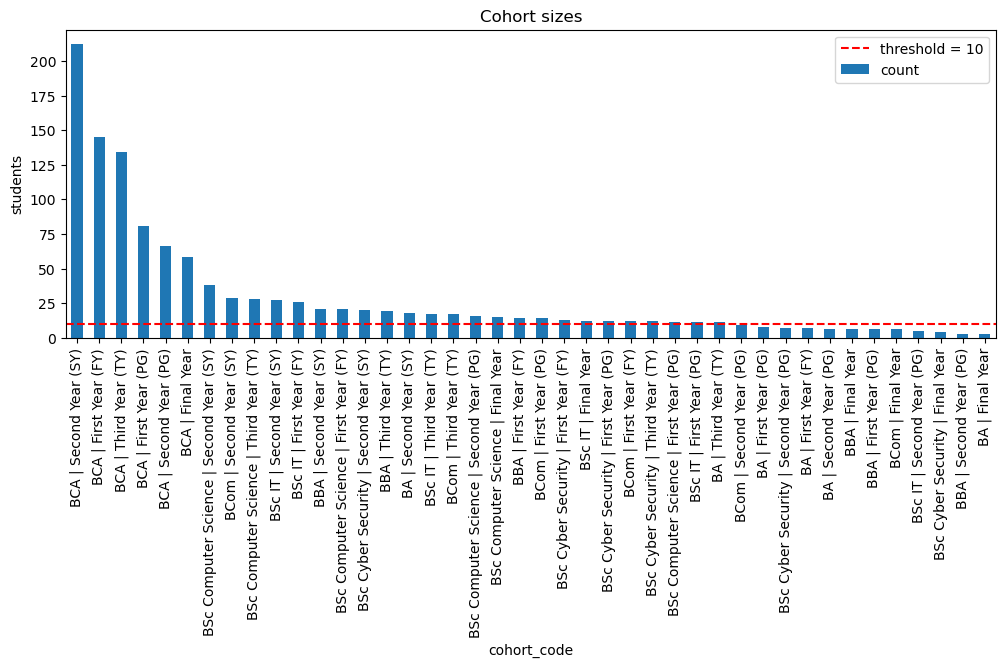

In [35]:
counts.plot(kind="bar", figsize=(12, 4))
plt.axhline(10, color="red", linestyle="--", label="threshold = 10")
plt.ylabel("students")
plt.title("Cohort sizes")
plt.legend()
plt.show()

### Check whether the file is already in chronological order

In [38]:
print("Already sorted by time?", data["timestamp"].is_monotonic_increasing)

Already sorted by time? True


In [39]:
# sorting

data = data.sort_values("timestamp").reset_index(drop=True)

print("Sorted now?", data["timestamp"].is_monotonic_increasing)
print(data[["timestamp", "submission_day"]].head())

Sorted now? True
            timestamp  submission_day
0 2026-03-15 01:07:00        0.000000
1 2026-03-15 06:48:00        0.236806
2 2026-03-15 07:56:00        0.284028
3 2026-03-15 08:53:00        0.323611
4 2026-03-15 09:03:00        0.330556


#### plot CGPA over time 

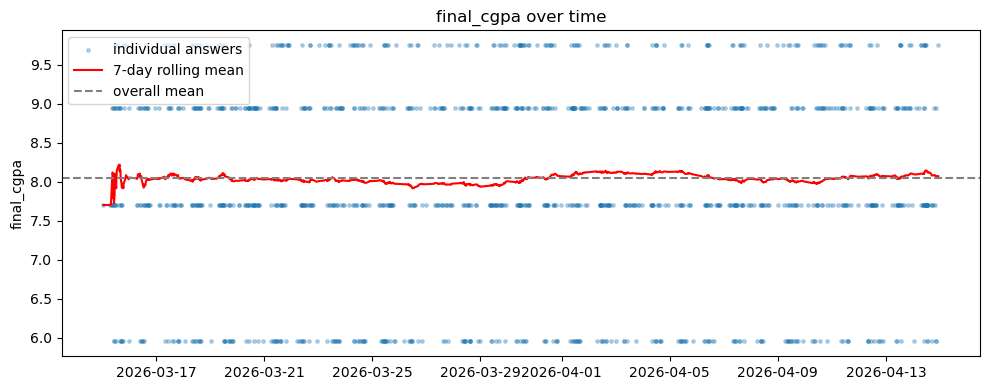

In [41]:
ts = data.set_index("timestamp")["final_cgpa"]
rolling = ts.rolling("7D").mean()

plt.figure(figsize=(10, 4))
plt.scatter(ts.index, ts.values, s=6, alpha=0.3, label="individual answers")
plt.plot(rolling.index, rolling.values, color="red", label="7-day rolling mean")
plt.axhline(ts.mean(), color="gray", linestyle="--", label="overall mean")
plt.ylabel("final_cgpa")
plt.title("final_cgpa over time")
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
n = len(data)
first = data["final_cgpa"].iloc[: int(0.8 * n)]
last  = data["final_cgpa"].iloc[int(0.8 * n):]

print("Mean CGPA, first 80% (future train):", round(first.mean(), 3))
print("Mean CGPA, last 20%  (future test): ", round(last.mean(), 3))
print("Corr(submission_day, final_cgpa):   ", round(data["submission_day"].corr(data["final_cgpa"]), 3))

print("\n there's no meaningful drift or trend")

Mean CGPA, first 80% (future train): 8.031
Mean CGPA, last 20%  (future test):  8.097
Corr(submission_day, final_cgpa):    0.02

 there's no meaningful drift or trend


**the risks found in the data and the leakage or overfitting
problem :**
- *Risk label* (`performance_risk_level`) is tied to the target → target leakage, fake high scores.
- *Rare cohorts* (X of 42 cohorts have fewer than 10 students) → a model can memorize tiny groups → overfitting.
- *Missing values* (2 to 5%) → if filled using the whole dataset, test information leaks into training.
- *Time order:* file not sorted → a random split mixes past and future. No drift found (corr 0.02), but `submission_day` only grows, so test values fall outside the training range (D.2).

## Part B. Impact of Data Leakage and Evaluation Strategy

### B.1 Compare splitting strategies

In [45]:
feature_cols = ["study_hours", "sleep_hours", "attendance_rate", "study_consistency",
                "tasks_on_time", "assignments_on_time", "revision_frequency",
                "career_goal_clarity", "daily_productivity", "stress_level", "age",
                "submission_day"]

X = data[feature_cols]
y = data["final_cgpa"]

# chronological split: data is already sorted by time
split = int(0.8 * len(data))
X_train_c, X_test_c = X.iloc[:split], X.iloc[split:]
y_train_c, y_test_c = y.iloc[:split], y.iloc[split:]

print("Train:", X_train_c.shape, " Test:", X_test_c.shape)

Train: (960, 12)  Test: (240, 12)


In [46]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def evaluate(model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    return (rmse(y_tr, model.predict(X_tr)),
            rmse(y_te, model.predict(X_te)),
            r2_score(y_te, model.predict(X_te)))

def tree_pipe():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(random_state=SEED)),
    ])

In [47]:
# baseline
base = DummyRegressor(strategy="mean")
base_tr, base_te, base_r2 = evaluate(base, X_train_c, X_test_c, y_train_c, y_test_c)

# Chronological split
chrono_tr, chrono_te, chrono_r2 = evaluate(tree_pipe(), X_train_c, X_test_c, y_train_c, y_test_c)

# Random split (80/20)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y, test_size=0.2, random_state=SEED)
rand_tr, rand_te, rand_r2 = evaluate(tree_pipe(), X_train_r, X_test_r, y_train_r, y_test_r)

results_B1 = pd.DataFrame({
    "strategy": ["Baseline (chronological)", "Tree - random split", "Tree - chronological split"],
    "train_RMSE": [base_tr, rand_tr, chrono_tr],
    "test_RMSE":  [base_te, rand_te, chrono_te],
    "test_R2":    [base_r2, rand_r2, chrono_r2],
}).round(3)
print(results_B1)

                     strategy  train_RMSE  test_RMSE  test_R2
0    Baseline (chronological)       1.269      1.236   -0.003
1         Tree - random split       0.000      1.606   -0.465
2  Tree - chronological split       0.000      1.975   -1.560


**Explaining the difference**
the two test RMSEs may differ for possible reasons:
- in a **random split** the test rows are mixed in time with the training rows, a student who answered at 10:00 is "surrounded" by training rows from 10:00, and `submission_day` lets the tree match neighbours in time
- in the **chronological split** the test rows are all in the future and `submission_day`is outside the training range. This is closer to real use so it's the more honest estimate.

### B.2 Investigate duplicate leakage

In [48]:
# augmented dataset

start, end = data["timestamp"].min(), data["timestamp"].max()
span = (end - start).total_seconds()

# 15% of rows, drawn at random
dup = data.sample(frac=0.15, random_state=SEED).copy()

# same answers, same student_id, but a new random timestamp in the survey period
rng = np.random.default_rng(SEED)
dup["timestamp"] = start + pd.to_timedelta(rng.uniform(0, span, len(dup)), unit="s")

# stack originals + copies, sort by time, recompute submission_day
aug = pd.concat([data, dup]).sort_values("timestamp").reset_index(drop=True)
aug["submission_day"] = (aug["timestamp"] - start).dt.total_seconds() / 86400

print("Original:", len(data), " Augmented:", len(aug))

Original: 1200  Augmented: 1380


In [49]:
# split before removing dups

def chrono_eval(df_):
    s = int(0.8 * len(df_))
    tr, te = df_.iloc[:s], df_.iloc[s:]
    res = evaluate(tree_pipe(), tr[feature_cols], te[feature_cols],
                   tr["final_cgpa"], te["final_cgpa"])
    return res, tr, te

res_before, tr_a, te_a = chrono_eval(aug)
print("Split before dedup -> train RMSE %.3f | test RMSE %.3f | R2 %.3f" % res_before)

Split before dedup -> train RMSE 0.000 | test RMSE 1.482 | R2 -0.348


In [50]:
# remove dups before spliting

# duplicate = same on every column EXCEPT timestamp (and submission_day, which comes from it)
subset = [c for c in aug.columns if c not in ["timestamp", "submission_day"]]

aug_dedup = aug.drop_duplicates(subset=subset, keep="first").reset_index(drop=True)
print("After dedup:", len(aug_dedup), "rows (should be 1200)")

res_after, tr_b, te_b = chrono_eval(aug_dedup)
print("Dedup before split -> train RMSE %.3f | test RMSE %.3f | R2 %.3f" % res_after)

After dedup: 1200 rows (should be 1200)
Dedup before split -> train RMSE 0.000 | test RMSE 1.718 | R2 -1.020


In [51]:
key = lambda d: d[subset].astype(str).apply("|".join, axis=1)

leak_a = key(te_a).isin(set(key(tr_a))).sum()
leak_b = key(te_b).isin(set(key(tr_b))).sum()

print(f"Test rows whose twin is in train, split before dedup: {leak_a} / {len(te_a)}")
print(f"Test rows whose twin is in train, dedup before split: {leak_b} / {len(te_b)}")

Test rows whose twin is in train, split before dedup: 50 / 276
Test rows whose twin is in train, dedup before split: 0 / 240


In [52]:
results_B2 = pd.DataFrame({
    "strategy": ["Split before dedup (leaky)", "Dedup before split (clean)"],
    "train_RMSE": [res_before[0], res_after[0]],
    "test_RMSE":  [res_before[1], res_after[1]],
    "test_R2":    [res_before[2], res_after[2]],
}).round(3)
print(results_B2)

                     strategy  train_RMSE  test_RMSE  test_R2
0  Split before dedup (leaky)         0.0      1.482   -0.348
1  Dedup before split (clean)         0.0      1.718   -1.020


- How a duplicate ends up in both sets: the copy has a new random timestamp. The split is by time, so the original may fall in the first 80% (train) and the copy in the last 20% (test). Same answers, same CGPA, on both sides.
- What it does to the score: the tree memorized the original, so it “predicts” the copy almost perfectly. Test RMSE looks lower (better) than it really is, and R² looks higher. That’s an inflated score caused by **leakage**, not better learning.

### B.3 Investigate preprocessing leakage

In [54]:
# LEAKY: median and scaler learned from ALL 1200 rows (train + test)
imp_all = SimpleImputer(strategy="median").fit(X)
X_filled = imp_all.transform(X)
scaler_all = StandardScaler().fit(X_filled)
X_scaled = scaler_all.transform(X_filled)

Xs_train, Xs_test = X_scaled[:split], X_scaled[split:]

knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(Xs_train, y_train_c)

leaky_tr = rmse(y_train_c, knn.predict(Xs_train))
leaky_te = rmse(y_test_c, knn.predict(Xs_test))
leaky_r2 = r2_score(y_test_c, knn.predict(Xs_test))
print("Leaky -> train RMSE %.3f | test RMSE %.3f | R2 %.3f" % (leaky_tr, leaky_te, leaky_r2))

Leaky -> train RMSE 1.069 | test RMSE 1.157 | R2 0.122


In [55]:
knn_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=10)),
])

clean_tr, clean_te, clean_r2 = evaluate(knn_pipe, X_train_c, X_test_c, y_train_c, y_test_c)
print("Clean -> train RMSE %.3f | test RMSE %.3f | R2 %.3f" % (clean_tr, clean_te, clean_r2))

Clean -> train RMSE 1.066 | test RMSE 1.147 | R2 0.137


In [56]:
results_B3 = pd.DataFrame({
    "strategy": ["KNN - scaler on all data (leaky)", "KNN - scaler in Pipeline (clean)"],
    "train_RMSE": [leaky_tr, clean_tr],
    "test_RMSE":  [leaky_te, clean_te],
    "test_R2":    [leaky_r2, clean_r2],
}).round(3)
print(results_B3)

summary_B = pd.concat([results_B1, results_B2, results_B3], ignore_index=True)
print()
print(summary_B)

                           strategy  train_RMSE  test_RMSE  test_R2
0  KNN - scaler on all data (leaky)       1.069      1.157    0.122
1  KNN - scaler in Pipeline (clean)       1.066      1.147    0.137

                           strategy  train_RMSE  test_RMSE  test_R2
0          Baseline (chronological)       1.269      1.236   -0.003
1               Tree - random split       0.000      1.606   -0.465
2        Tree - chronological split       0.000      1.975   -1.560
3        Split before dedup (leaky)       0.000      1.482   -0.348
4        Dedup before split (clean)       0.000      1.718   -1.020
5  KNN - scaler on all data (leaky)       1.069      1.157    0.122
6  KNN - scaler in Pipeline (clean)       1.066      1.147    0.137


**Explanation :**
- *B1* : The unlimited tree memorizes the training set (train RMSE 0.000) but fails on new data: test RMSE is 1.606 (random split) and 1.975 (chronological), both worse than the baseline of 1.236, with negative R². That is overfitting. The chronological split is worse, likely because `submission_day` helps in a random split (training neighbours from the same days) but is out of range in a chronological one. The chronological score is the more honest estimate.
- *B2* : Splitting before removing duplicates gives test RMSE 1.482, versus 1.718 after deduplicating first. A copy gets a random timestamp, so the original can land in train and its twin in test, and the tree has memorized the answer. That makes the score look about 0.24 better than it really is. Removing duplicates before splitting removes the leak.
- *B3* : Scaler fitted on all data gives test RMSE 1.157, versus 1.147 in the Pipeline. The gap is tiny because 960 rows have almost the same mean and std as 1200. The principle still matters: test data must not influence any learned statistic (median, mean, std). In real use, future data doesn’t exist at training time. A Pipeline guarantees this.

## Part C. Understanding and Diagnosing Overfitting

In [57]:
# train a tree for each depth

depths = [1, 2, 3, 5, 10, 20, None]
rows = []

for d in depths:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(max_depth=d, random_state=SEED)),
    ])
    tr, te, r2 = evaluate(pipe, X_train_c, X_test_c, y_train_c, y_test_c)
    rows.append({"max_depth": "None" if d is None else d,
                 "train_RMSE": tr, "test_RMSE": te,
                 "gap": te - tr, "test_R2": r2})

results_C1 = pd.DataFrame(rows).round(3)
print(results_C1)
print("\nBaseline test RMSE:", round(base_te, 3))

  max_depth  train_RMSE  test_RMSE    gap  test_R2
0         1       1.179      1.159 -0.020    0.118
1         2       1.139      1.127 -0.013    0.167
2         3       1.102      1.068 -0.034    0.252
3         5       1.009      1.335  0.326   -0.170
4        10       0.539      1.936  1.397   -1.459
5        20       0.000      1.975  1.975   -1.560
6      None       0.000      1.975  1.975   -1.560

Baseline test RMSE: 1.236


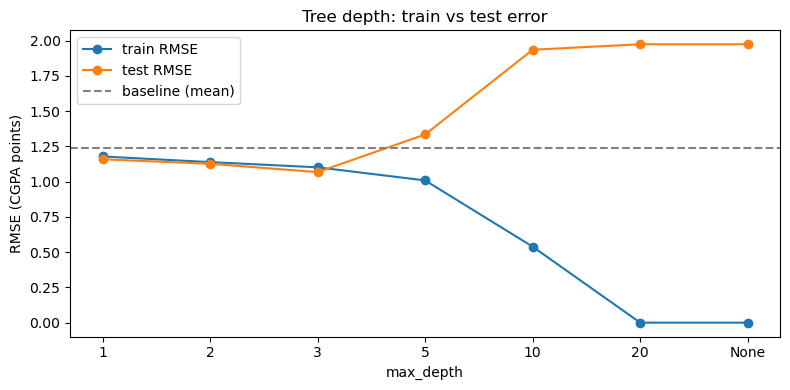

In [58]:
x_labels = results_C1["max_depth"].astype(str)

plt.figure(figsize=(8, 4))
plt.plot(x_labels, results_C1["train_RMSE"], marker="o", label="train RMSE")
plt.plot(x_labels, results_C1["test_RMSE"], marker="o", label="test RMSE")
plt.axhline(base_te, color="gray", linestyle="--", label="baseline (mean)")
plt.xlabel("max_depth")
plt.ylabel("RMSE (CGPA points)")
plt.title("Tree depth: train vs test error")
plt.legend()
plt.tight_layout()
plt.show()

In [59]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# effort_index for the training part only (data is sorted, so first `split` rows)
Xe_train = data[["effort_index"]].iloc[:split]
Xe_test  = data[["effort_index"]].iloc[split:]

tscv = TimeSeriesSplit(n_splits=5)
degrees = [1, 2, 3, 5, 9, 15]
cv_rmse = []

for deg in degrees:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=deg, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ])
    scores = cross_val_score(pipe, Xe_train, y_train_c, cv=tscv,
                             scoring="neg_root_mean_squared_error")
    cv_rmse.append(-scores.mean())

results_C2 = pd.DataFrame({"degree": degrees, "CV_RMSE": cv_rmse}).round(4)
print(results_C2)

   degree  CV_RMSE
0       1   1.1774
1       2   1.1776
2       3   1.1789
3       5   1.1854
4       9   1.1883
5      15   1.2942


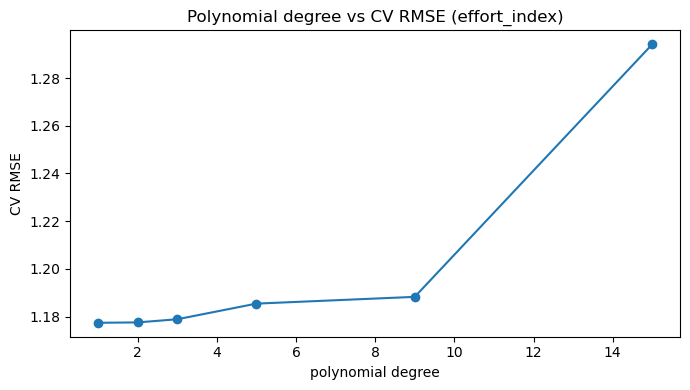

In [60]:
plt.figure(figsize=(7, 4))
plt.plot(degrees, cv_rmse, marker="o")
plt.xlabel("polynomial degree")
plt.ylabel("CV RMSE")
plt.title("Polynomial degree vs CV RMSE (effort_index)")
plt.tight_layout()
plt.show()

**C1** : Train RMSE decreases steadily with depth, reaching 0 at depth 20, because deeper trees memorize the training students. Test RMSE is best at depth 3 (1.068, R² 0.252), better than the baseline (1.236). From depth 5 on, test RMSE rises above the baseline and R² goes negative. The gap is negative or near 0 for depths 1 to 3 (underfitting or good fit), then jumps to 0.326 at depth 5, 1.397 at depth 10 and 1.975 at depth 20/None. The model starts to overfit at depth 5, and depth 3 is the best complexity. Depths 20 and None give identical results because the tree has already reached pure leaves.

**C2** : CV RMSE is lowest at degree 1 (1.1774) and stays almost flat up to degree 9 (1.1883). It only rises noticeably at degree 15 (1.2942), where the curve starts chasing noise. The extra complexity adds nothing: a straight line is already as good as any curve, so effort_index has a simple, weak linear relation with CGPA. The effect is small compared with C.1, where test RMSE went from 1.07 to 1.98 (+0.9), versus +0.12 here. The reason is that there is only one input feature, and effort_index is a smooth variable with few distinct values, so even a high-degree polynomial can only bend one curve. A deep tree can instead carve out tiny groups of students and memorize each one.

## Part D. Improving Model Generalization

### D.1 Handling a high-cardinality categorical feature

In [62]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

cat_col = ["cohort_code"]
X_all = data[feature_cols + cat_col]
Xtr_all, Xte_all = X_all.iloc[:split], X_all.iloc[split:]

tscv = TimeSeriesSplit(n_splits=5)

In [63]:
def make_pipe(cat_encoder):
    num_part = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    transformers = [("num", num_part, feature_cols)]
    if cat_encoder is not None:
        transformers.append(("cat", cat_encoder, cat_col))
    return Pipeline([
        ("prep", ColumnTransformer(transformers)),
        ("model", DecisionTreeRegressor(max_depth=5, random_state=SEED)),
    ])

approaches = {
    "Rare grouping (one-hot)": OneHotEncoder(min_frequency=10,
                                             handle_unknown="infrequent_if_exist",
                                             sparse_output=False),
    "Target encoding": TargetEncoder(cv=5, shuffle=False),
    "Feature removal": None,
}

rows = []
for name, enc in approaches.items():
    scores = cross_val_score(make_pipe(enc), Xtr_all, y_train_c, cv=tscv,
                             scoring="neg_root_mean_squared_error")
    rows.append({"approach": name, "CV_RMSE": -scores.mean(), "std": scores.std()})

results_D1 = pd.DataFrame(rows).round(4)
print(results_D1)

                  approach  CV_RMSE     std
0  Rare grouping (one-hot)   1.2368  0.1145
1          Target encoding   1.3004  0.0900
2          Feature removal   1.2549  0.0875


Rare grouping is best (CV RMSE 1.2368), then Feature removal (1.2549), then Target encoding (1.3004).

Rare-category grouping gives the lowest validation RMSE (1.2368), followed by feature removal (1.2549) and target encoding (1.3004). However, the fold-to-fold std (0.09 to 0.11) is larger than the gap between the first two, so rare grouping is only marginally better than dropping the feature. Target encoding is the worst: replacing each cohort by its mean CGPA lets the tree rely on noisy averages from small groups. This shows that `cohort_code` carries little useful information about CGPA. We keep rare grouping as the best treatment, since it has the lowest RMSE, and it is a safe way to handle rare categories.

### D.2 Feature selection

In [64]:
from sklearn.ensemble import GradientBoostingRegressor

feats_with = feature_cols
feats_without = [c for c in feature_cols if c != "submission_day"]

models = {
    "Linear Regression": lambda: LinearRegression(),
    "Decision Tree (depth 5)": lambda: DecisionTreeRegressor(max_depth=5, random_state=SEED),
    "Gradient Boosting": lambda: GradientBoostingRegressor(
        n_estimators=60, learning_rate=0.05, max_depth=3, random_state=SEED),
}

def cv_rmse_for(model_fn, feats):
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model_fn()),
    ])
    s = cross_val_score(pipe, data[feats].iloc[:split], y_train_c, cv=tscv,
                        scoring="neg_root_mean_squared_error")
    return -s.mean()

rows = []
for name, fn in models.items():
    rows.append({"model": name,
                 "with_submission_day": cv_rmse_for(fn, feats_with),
                 "without_submission_day": cv_rmse_for(fn, feats_without)})

results_D2 = pd.DataFrame(rows).round(4)
print(results_D2)

                     model  with_submission_day  without_submission_day
0        Linear Regression               1.1258                  1.1182
1  Decision Tree (depth 5)               1.2549                  1.2015
2        Gradient Boosting               1.1416                  1.1275


Removing `submission_day` lowers validation RMSE for all three models (Linear Regression 1.1258 → 1.1182, Decision Tree 1.2549 → 1.2015, Gradient Boosting 1.1416 → 1.1275). The gain is largest for the tree, which can split on the date and memorize time-specific patterns. This fits Part A, where the correlation with CGPA was about 0.02, so the feature carries no real signal. It also increases in time, so in a chronological split every test value lies beyond the training range and the model can’t use it. We drop `submission_day` for the rest of the session.

### D.3 Applying regularization

In [65]:
from sklearn.linear_model import Ridge, Lasso

alphas = [0.001, 0.01, 0.1, 1, 10, 100]

def poly_pipe(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=5, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

def cv_score(pipe):
    s = cross_val_score(pipe, Xe_train, y_train_c, cv=tscv,
                        scoring="neg_root_mean_squared_error")
    return -s.mean()

rows = [{"model": "Linear", "alpha": "-", "CV_RMSE": cv_score(poly_pipe(LinearRegression()))}]
for a in alphas:
    rows.append({"model": "Ridge", "alpha": a, "CV_RMSE": cv_score(poly_pipe(Ridge(alpha=a)))})
for a in alphas:
    rows.append({"model": "Lasso", "alpha": a,
                 "CV_RMSE": cv_score(poly_pipe(Lasso(alpha=a, max_iter=100000)))})

results_D3 = pd.DataFrame(rows).round(4)
print(results_D3)

     model  alpha  CV_RMSE
0   Linear      -   1.1854
1    Ridge  0.001   1.1808
2    Ridge   0.01   1.1800
3    Ridge    0.1   1.1790
4    Ridge      1   1.1784
5    Ridge     10   1.1782
6    Ridge    100   1.1805
7    Lasso  0.001   1.1781
8    Lasso   0.01   1.1771
9    Lasso    0.1   1.1772
10   Lasso      1   1.2680
11   Lasso     10   1.2680
12   Lasso    100   1.2680


In [66]:
best_ridge_a = results_D3[results_D3.model == "Ridge"].sort_values("CV_RMSE").iloc[0]["alpha"]
best_lasso_a = results_D3[results_D3.model == "Lasso"].sort_values("CV_RMSE").iloc[0]["alpha"]
print("Best Ridge alpha:", best_ridge_a, "| Best Lasso alpha:", best_lasso_a)

lin = poly_pipe(LinearRegression()).fit(Xe_train, y_train_c)
rid = poly_pipe(Ridge(alpha=best_ridge_a)).fit(Xe_train, y_train_c)
las = poly_pipe(Lasso(alpha=best_lasso_a, max_iter=100000)).fit(Xe_train, y_train_c)

coefs = pd.DataFrame({
    "Linear": lin["model"].coef_,
    "Ridge":  rid["model"].coef_,
    "Lasso":  las["model"].coef_,
}, index=[f"effort^{i}" for i in range(1, 6)]).round(3)
print(coefs)
print("\nLasso coefficients exactly 0:", (las["model"].coef_ == 0).sum(), "out of 5")

Best Ridge alpha: 10 | Best Lasso alpha: 0.01
          Linear  Ridge  Lasso
effort^1   8.831  0.394  0.471
effort^2 -37.753  0.156  0.000
effort^3  66.183  0.015  0.000
effort^4 -52.515 -0.049 -0.000
effort^5  15.761 -0.049 -0.000

Lasso coefficients exactly 0: 4 out of 5


Both regularized models beat the unregularized one (CV RMSE 1.1854). The best Ridge (α=10) gets 1.1782 and the best Lasso (α=0.01) gets 1.1771. The unregularized model has very large, alternating coefficients (from 8.8 to -52.5) that cancel each other to fit noise. Ridge shrinks all coefficients to small values (below 0.4) without setting any to zero. Lasso sets 4 of the 5 coefficients exactly to zero and keeps only the linear term of `effort_index`. This confirms C.2: a straight line is enough, and the higher powers only add noise. For large α (≥1) Lasso removes every term and predicts the mean, so its RMSE rises to 1.2680.

### D.4 Comparing the final models

In [67]:
final_num = [c for c in feature_cols if c != "submission_day"]
final_cat = ["cohort_code"]
X_fin = data[final_num + final_cat]
Xtr_f, Xte_f = X_fin.iloc[:split], X_fin.iloc[split:]

def prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), final_num),
        ("cat", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist",
                              sparse_output=False), final_cat),
    ])

def full_pipe(model):
    return Pipeline([("prep", prep()), ("model", model)])

In [68]:
def cv_f(model):
    s = cross_val_score(full_pipe(model), Xtr_f, y_train_c, cv=tscv,
                        scoring="neg_root_mean_squared_error")
    return -s.mean()

# Ridge or Lasso: pick the best alpha among both
cands = [("Ridge", a, cv_f(Ridge(alpha=a))) for a in alphas] + \
        [("Lasso", a, cv_f(Lasso(alpha=a, max_iter=100000))) for a in alphas]
best_rl = min(cands, key=lambda t: t[2])
print("Best Ridge/Lasso:", best_rl)

# Decision tree: pick best max_depth among C.1 values
depth_list = [1, 2, 3, 5, 10, 20, None]
tree_cv = [(d, cv_f(DecisionTreeRegressor(max_depth=d, random_state=SEED))) for d in depth_list]
best_depth = min(tree_cv, key=lambda t: t[1])[0]
print("Best depth:", best_depth, tree_cv)

Best Ridge/Lasso: ('Lasso', 0.1, np.float64(1.1072913789794698))
Best depth: 3 [(1, np.float64(1.179902768441929)), (2, np.float64(1.1619914831990585)), (3, np.float64(1.1552376513607387)), (5, np.float64(1.20021953802525)), (10, np.float64(1.4590640707776525)), (20, np.float64(1.5395502092016466)), (None, np.float64(1.5395502092016466))]


In [69]:
# last 15% of the training set = validation block
cut = int(0.85 * len(Xtr_f))
Xa, Xv = Xtr_f.iloc[:cut], Xtr_f.iloc[cut:]
ya, yv = y_train_c.iloc[:cut], y_train_c.iloc[cut:]

gb_big = full_pipe(GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEED)).fit(Xa, ya)

Xv_t = gb_big["prep"].transform(Xv)
val_rmse = [rmse(yv, p) for p in gb_big["model"].staged_predict(Xv_t)]
best_n = int(np.argmin(val_rmse)) + 1
print("Best number of trees:", best_n)

# refit on the full training set with that number
gb_final = full_pipe(GradientBoostingRegressor(
    n_estimators=best_n, learning_rate=0.05, max_depth=3, random_state=SEED))

Best number of trees: 135


In [70]:
rl_model = Ridge(alpha=best_rl[1]) if best_rl[0] == "Ridge" else Lasso(alpha=best_rl[1], max_iter=100000)

final_models = {
    "Baseline (training mean)": Pipeline([("model", DummyRegressor(strategy="mean"))]),
    "Linear Regression": full_pipe(LinearRegression()),
    f"{best_rl[0]} (alpha={best_rl[1]})": full_pipe(rl_model),
    f"Decision Tree (depth={best_depth})": full_pipe(DecisionTreeRegressor(max_depth=best_depth, random_state=SEED)),
    f"Gradient Boosting ({best_n} trees)": gb_final,
}

rows = []
for name, m in final_models.items():
    tr, te, r2 = evaluate(m, Xtr_f, Xte_f, y_train_c, y_test_c)
    rows.append({"model": name, "train_RMSE": tr, "test_RMSE": te, "test_R2": r2})

results_D4 = pd.DataFrame(rows).round(3)
results_D4["gap"] = (results_D4.test_RMSE - results_D4.train_RMSE).round(3)
print(results_D4)

                           model  train_RMSE  test_RMSE  test_R2    gap
0       Baseline (training mean)       1.269      1.236   -0.003 -0.033
1              Linear Regression       1.072      1.085    0.227  0.013
2              Lasso (alpha=0.1)       1.106      1.072    0.246 -0.034
3        Decision Tree (depth=3)       1.102      1.068    0.252 -0.034
4  Gradient Boosting (135 trees)       0.955      1.059    0.263  0.104
